# 10 · One interface for every method, the two baselines, and the pipeline

**The question this step answers:** how does an account go all the way from its name to a decision (*auto-mapped* or *sent to review*), and how good are the two simplest methods at it?
- **embeddings:** take the shortlist's number 1 (notebook 07).
- **fuzzy:** ignore the embeddings and compare *letters* with all 190 group names, in all three languages.

Every later method (XGBoost, random forest, Laya, the LLM) plugs into the same interface and has to beat these two.

**Where it sits in the pipeline:** it joins the earlier steps into one machine:

```
account name -> shortlist (07) -> a method scores and picks -> calibration (09) -> auto or review
```

**The code:**
- `src/d1/mapper/methods/`: the interface (`base.py`) and the two baselines (`baselines.py`);
- `src/d1/mapper/pipeline.py`: the `Mapper`, which runs the chain above;
- `src/d1/mapper/train.py`: `python -m d1.mapper.train --method …` calibrates a method on dev and saves it in `artifacts/methods/<method>/`.

*Running this notebook loads bge-m3, like notebook 07.*

> **Re-run after step 12 and the name cleanup (2026-11-06).** The baselines here use `group_text: average` from step 12: each group is scored on its names and on its names plus description, and the two scores are averaged. The account names are the cleaned ones, without company, bank or brand names (notebook 04, section 3b).

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

import contextlib, io, warnings
warnings.filterwarnings("ignore")
from d1.datagen.schema import read_jsonl
from d1.evaluation.plotting import METHOD_COLORS
from d1.mapper.embed import SentenceTransformerEmbedder
from d1.mapper.methods.base import accounts_from_rows
from d1.mapper.pipeline import Mapper, artifact_dir

TARGET = config.models.mapping.target_precision
embedder = SentenceTransformerEmbedder(config.models.embedding_model)
with contextlib.redirect_stderr(io.StringIO()):  # hide the model's loading messages
    embedder.encode(["warm-up"], "query")
shared = lambda name: embedder  # both mappers use the one loaded model
mappers = {m: Mapper.from_artifacts(config, m, embedder_factory=shared) for m in ["fuzzy", "embeddings"]}
dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
dev_by_id = {r.account_id: r for r in dev}

## 1. One account through the whole chain

An LLM-written dev account of a construction company:

In [2]:
row = next(r for r in dev if r.name == "WIP werf Anderlecht - Rue Wayez")
(account,) = accounts_from_rows([r for r in dev if r.company_id == row.company_id])[int(row.account_id[-3:]):][:1]
display(pd.Series({"name": account.name, "code": account.code, "neighbours (for the LLM later)": " | ".join(account.neighbours),
                   "right group": f"{row.target_code} {by_code[row.target_code].name_en}"}, name=account.account_id).to_frame())

,dev-c041-008
name,WIP werf Anderlecht - Rue Wayez
code,320100
neighbours (for the LLM later),Leasing torenkraan | Leasing graafmachine | En-cours chantier Uccle - Av. Brugmann | S...
right group,320 Work in Progress - Acquisition Value


The account goes in as an `AccountIn`: its name, its code, its company, and the names of the accounts just before and after it in the company's chart. The baselines ignore the neighbours; the LLM will use them later, since "WIP werf Anderlecht" next to "WIP werf Uccle" says a lot.

**Step 1, the shortlist**, then **step 2, each method scores and picks**:

In [3]:
(shortlist,) = mappers["embeddings"].retriever.top_k([account.name], config.models.mapping.candidates_k)
for name, mapper in mappers.items():
    (out,) = mapper.method.score([account], [shortlist])
    top = list(out.scores.items())[:4]
    print(f"{name:10}  pick: {out.chosen_code} {by_code[out.chosen_code].name_en}")
    print(" " * 12 + "scores: " + ", ".join(f"{c} {s:.3f}" for c, s in top) + ", …")

fuzzy       pick: 220 Land
            scores: 220 0.733, 284 0.540, 400 0.496, 451 0.491, …
embeddings  pick: 320 Work in Progress - Acquisition Value
            scores: 320 0.452, 499 0.443, 370 0.428, 493 0.413, …


- **embeddings** takes bge-m3's number 1 from the shortlist.
- **fuzzy** never looks at the shortlist. It compares the letters of "WIP werf Anderlecht - Rue Wayez" with every group's English, Dutch and French name and keeps its own top 10. With almost no letters in common, its scores are low and its pick is close to a guess.

**Steps 3 and 4: calibration and the decision.** Each method's calibrator turns its top score and lead into P(right), and each method's own threshold decides:

In [4]:
rows_out = []
for name, mapper in mappers.items():
    (d,) = mapper.map([account])
    rows_out.append({"method": name, "pick": f"{d.chosen_code} {by_code[d.chosen_code].name_en}", "right?": "✔" if d.chosen_code == row.target_code else "✘",
                     "P(right)": f"{d.confidence:.1%}", "threshold": f"{mapper.thresholds.t_auto:.3f}", "decision": d.decision_path})
display(pd.DataFrame(rows_out).set_index("method"))

,pick,right?,P(right),threshold,decision
method,,,,,
fuzzy,220 Land,✘,15.5%,0.876,review
embeddings,320 Work in Progress - Acquisition Value,✔,18.0%,0.928,review


Neither method is sure enough, so the account goes to a person: the safe outcome. The embeddings pick is even right, but at P(right) 18% the method can't know that. The decision also records which model versions made it (`model_versions`), so any mapping can be traced back later:

In [5]:
print(json.dumps(mappers["embeddings"].map([account])[0].model_versions, indent=2))

{
  "embedder": "BAAI/bge-m3",
  "method": "embeddings-top1-v1",
  "calibrator": "18cccdc2d362"
}


## 2. What training saved

`python -m d1.mapper.train --method fuzzy` and `--method embeddings` calibrated each method on all 3,500 dev accounts (out of fold, companies kept together, as in notebook 09) and saved four small files per method in `artifacts/methods/<method>/`:

In [6]:
for name in mappers:
    folder = artifact_dir(config, name)
    print(f"--- {folder.relative_to(REPO_ROOT)}")
    for f in ["method.json", "calibrator.json", "thresholds.json"]:
        print(f"{f:16} {json.dumps(json.loads((folder / f).read_text()))}")

--- artifacts/methods/fuzzy
method.json      {"method": "fuzzy", "version": "fuzzy-wratio-k10-v1", "params": {"k": 10}}
calibrator.json  {"type": "logistic", "features": ["s1", "s1_minus_s2"], "coef": [17.47206270545354, 6.76576825032809], "intercept": -15.807562877269032, "n_fitted": 3500}
thresholds.json  {"method": "fuzzy", "t_auto": 0.875874049216863, "t_llm": null, "target_precision": 0.98, "fitted_on": "dev", "embedding_model": "BAAI/bge-m3", "group_text": "average"}
--- artifacts/methods/embeddings
method.json      {"method": "embeddings", "version": "embeddings-top1-v1", "params": {}}
calibrator.json  {"type": "logistic", "features": ["s1", "s1_minus_s2"], "coef": [10.480802918226873, 40.477030661380894], "intercept": -6.610383620005999, "n_fitted": 3500}
thresholds.json  {"method": "embeddings", "t_auto": 0.9281479086042382, "t_llm": null, "target_precision": 0.98, "fitted_on": "dev", "embedding_model": "BAAI/bge-m3", "group_text": "average"}


- **method.json:** which method, which version, its settings.
- **calibrator.json:** the three numbers of its calibration formula.
- **thresholds.json:** its threshold, the target, that it was fitted on dev, and the embedding model and group text its shortlists came from. Loading it with a different setting is refused, because every score would silently change.

The embeddings threshold (0.928) is not notebook 09's 0.954. Notebook 09 calibrates shortlists built from the group names only; the saved method uses the `average` group text of step 12. The training command does the same steps as notebook 09, starting from different scores.

## 3. How good are the two baselines?

Both methods on all 3,500 dev accounts, from their saved summaries:

In [7]:
summaries = {m: json.loads((artifact_dir(config, m) / "dev_summary.json").read_text()) for m in mappers}
table = pd.DataFrame({m: {"top-1 (pick right)": s["top1"], "auto-mapped": s["auto_share"], "precision of auto-mapped": s["auto_precision"],
                          "threshold": s["t_auto"]} for m, s in summaries.items()}).T
display(table.style.format({"top-1 (pick right)": "{:.1%}", "auto-mapped": "{:.1%}", "precision of auto-mapped": "{:.1%}", "threshold": "{:.3f}"}))

,top-1 (pick right),auto-mapped,precision of auto-mapped,threshold
fuzzy,57.9%,31.6%,98.6%,0.876
embeddings,70.3%,32.1%,98.0%,0.928


On the overall numbers the two baselines **look even**: each auto-maps about a third of dev at 98% precision (fuzzy 31.6%, embeddings 32.1%). That hides where the work gets done. Split by who wrote the account:

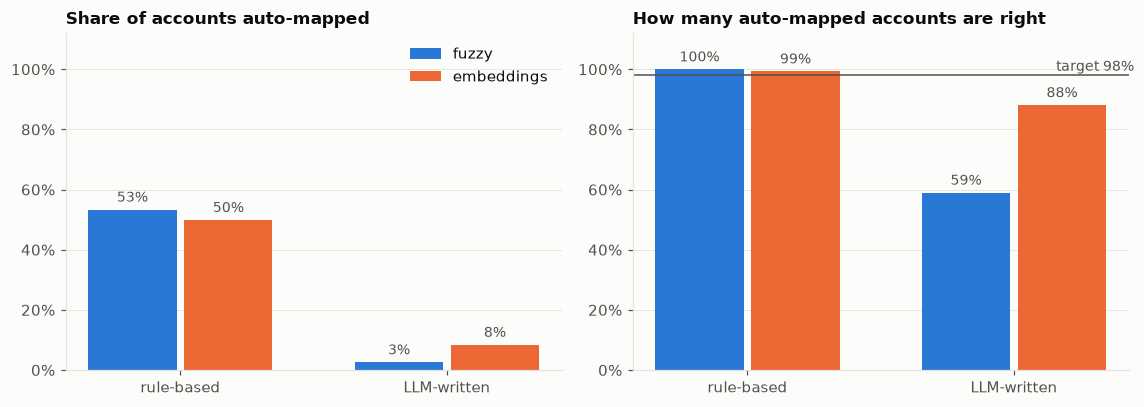

In [8]:
sources = ["rules", "llm"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
x = np.arange(len(sources))
width = 0.36
for i, m in enumerate(mappers):
    s = summaries[m]["by_source"]
    share = [s[src]["auto_share"] for src in sources]
    prec = [s[src]["auto_precision"] for src in sources]
    b1 = axes[0].bar(x + (i - 0.5) * width, share, width * 0.92, color=METHOD_COLORS[m], label=m)
    b2 = axes[1].bar(x + (i - 0.5) * width, prec, width * 0.92, color=METHOD_COLORS[m], label=m)
    axes[0].bar_label(b1, labels=[f"{v:.0%}" for v in share], padding=3, fontsize=9, color=INK_2)
    axes[1].bar_label(b2, labels=[f"{v:.0%}" for v in prec], padding=3, fontsize=9, color=INK_2)
axes[1].axhline(TARGET, color=INK_2, linewidth=1)
axes[1].text(1.45, TARGET + 0.015, f"target {TARGET:.0%}", ha="right", fontsize=9, color=INK_2)
for ax, title in [(axes[0], "Share of accounts auto-mapped"), (axes[1], "How many auto-mapped accounts are right")]:
    ax.set_xticks(x, ["rule-based", "LLM-written"])
    ax.yaxis.set_major_formatter(pct())
    ax.set_ylim(0, 1.12)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

**This is the main finding of this notebook.**
- **On rule-based accounts**, fuzzy is excellent: their names are the official names with a typo or an abbreviation, which is exactly what letter-matching catches. It auto-maps more than half (53%), all of them right.
- **On LLM-written accounts**, the realistic ones, both auto-map little: embeddings 8.4% of them at 88% precision, fuzzy 2.6% at **59%**. One threshold over all of dev is set mostly by the easy accounts, and it lets confident mistakes on hard accounts through, fuzzy's above all.

The bar stays one 98% over all accounts together, decided before Task 3.5: the LLM-written accounts are the closest to real life, so they belong in the same bar rather than in a separate, looser one. Precision per source is reported next to it in every run, so a weak spot like this one stays in sight.

**Would real company names help fuzzy?** These account names were cleaned of bank, supplier, brand and company names (notebook 04, section 3b). On the 280 dev accounts that had one, fuzzy did slightly *worse* with the names: top-1 12.9% against 15.4% without, and only 4 of its 8 auto-mapped picks right, against 5 of 5 without. The 190 standard groups contain no company names, so a name in an account gives fuzzy letters to latch onto that point nowhere useful. (Measured once, during the cleanup; the old names are no longer in the repo.)

Matching on names *is* fuzzy's strength in the next task, **intercompany matching (Phase 4)**. A booking like "Loan to X NV" has to be matched to the group company actually called X NV: a list of real names, where letter-matching catches abbreviations and typos.

## 4. Do the two methods agree?

For every dev account: is each method's pick right?

In [9]:
decisions = {m: mapper.map(accounts_from_rows(dev)) for m, mapper in mappers.items()}
right = pd.DataFrame({m: [d.chosen_code == dev_by_id[d.account_id].target_code for d in ds] for m, ds in decisions.items()})
right["source"] = [dev_by_id[d.account_id].source for d in decisions["fuzzy"]]
both = pd.crosstab(right["fuzzy"].map({True: "fuzzy right", False: "fuzzy wrong"}), right["embeddings"].map({True: "embeddings right", False: "embeddings wrong"}))
display(both)
print(f"at least one of the two right: {(right['fuzzy'] | right['embeddings']).mean():.1%}")

embeddings,embeddings right,embeddings wrong
fuzzy,,
fuzzy right,1869,158
fuzzy wrong,591,882


at least one of the two right: 74.8%


They are right on different accounts, so they make different mistakes. That's useful later: the XGBoost and random-forest methods get **both** signals as features (the cosine *and* a fuzzy string score), so they can learn when to trust which.

A few accounts where they disagree:

In [10]:
pick = {m: {d.account_id: d.chosen_code for d in ds} for m, ds in decisions.items()}
def show(ids):
    return pd.DataFrame([{"account": dev_by_id[i].name, "source": dev_by_id[i].source, "right group": dev_by_id[i].target_code,
                          "fuzzy": pick["fuzzy"][i], "embeddings": pick["embeddings"][i]} for i in ids])
ids = [d.account_id for d in decisions["fuzzy"]]
only_fuzzy = [i for i, f, e in zip(ids, right["fuzzy"], right["embeddings"]) if f and not e]
only_emb = [i for i, f, e in zip(ids, right["fuzzy"], right["embeddings"]) if e and not f]
display(Markdown("**Only fuzzy right:**"))
display(show(only_fuzzy[:5]))
display(Markdown("**Only embeddings right:**"))
display(show([i for i in only_emb if dev_by_id[i].source == "llm"][:5]))

**Only fuzzy right:**

,account,source,right group,fuzzy,embeddings
0,ANDERE VORD.,rules,285,285,700
1,TERMIJNREKENINGEN OP MEER DAN ÉÉN JAAR,rules,530,530,531
2,minderwaarden bij de courante,rules,641,641,642
3,Créances commerciales - Réduct,rules,409,409,290
4,ecrts de conversion des devises,rules,655,655,755


**Only embeddings right:**

,account,source,right group,fuzzy,embeddings
0,Bond loan 2024-2029 4.25%,llm,171,220,171
1,Land - Gent HQ Kortrijksesteenweg,llm,222,220,222
2,LT loan subsidiary 2,llm,281,220,281
3,Write-down resale licences & devices,llm,349,124,349
4,Corp. tax prepayments to recover,llm,412,649,412


## 5. What is *not* happening

- **No method is chosen here.** These are the baselines. `selected_method` in `config/models.yaml` stays empty until the comparison in Task 3.5.
- **Nothing is learned from the training data yet.** Both baselines work without training. XGBoost and the random forest (Phase 3) are the first methods fitted on the 12,000 training accounts.
- **Test is not touched.** Thresholds come from dev only. The metrics with confidence intervals and the guarded test run come in the next step (Task 2.5).